# 01 - Data Understanding (BijliCast)

**CT-378 Phase 2: EDA - step 1**

Goal: understand the combined hourly dataset built by `src/data_prep.py` from
59 LUMS REWD-P household files + 6 Open-Meteo ERA5 city weather files.

Covers the CT-378 EDA requirements: **distributions**, **missing values**, and a first look at data scale.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Locate repo root (works whether run from notebooks/ or repo root)
ROOT = Path.cwd()
while not (ROOT / "datasets").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Repo root:", ROOT)
print("Figures  :", FIG)

df = pd.read_parquet(ROOT / "data" / "processed" / "hourly_combined.parquet")
df["datetime"] = pd.to_datetime(df["datetime"])
print("Dataset:", df.shape)
df.head()

Repo root: D:\BijliCast
Figures  : D:\BijliCast\reports\figures


Dataset: (515786, 12)


,datetime,usage_kw,house_id,city,temperature,humidity,dew,precipitation,wind_speed,wind_direction,pressure,solar_radiation
0,2023-11-01 00:00:00,0.525333,House#41,Islamabad,17.9,75,13.5,0.0,5.2,344,957.3,0.0
1,2023-11-01 01:00:00,0.560500,House#41,Islamabad,18.2,72,13.2,0.0,6.2,339,957.3,0.0
2,2023-11-01 02:00:00,0.593833,House#41,Islamabad,18.6,70,13.1,0.0,5.0,330,957.3,0.0
3,2023-11-01 03:00:00,0.587667,House#41,Islamabad,19.3,67,13.1,0.0,3.7,331,957.4,0.0
4,2023-11-01 04:00:00,0.594000,House#41,Islamabad,17.9,74,13.2,0.0,3.9,326,957.1,0.0


## 1. Dataset overview

In [2]:
print("Rows:", len(df))
print("Columns:", list(df.columns))
print("Cities:", sorted(df["city"].unique()))
print("Houses:", df["house_id"].nunique())
print("Date range:", df["datetime"].min(), "->", df["datetime"].max())
print()
print(df.dtypes)
print()
df.drop(columns=["datetime"]).describe(include="all").T

Rows: 515786
Columns: ['datetime', 'usage_kw', 'house_id', 'city', 'temperature', 'humidity', 'dew', 'precipitation', 'wind_speed', 'wind_direction', 'pressure', 'solar_radiation']
Cities: ['Islamabad', 'Karachi', 'Lahore', 'Multan', 'Peshawar', 'Skardu']
Houses: 59
Date range: 2023-07-16 00:00:00 -> 2024-11-28 23:00:00

datetime           datetime64[us]
usage_kw                  float64
house_id                      str
city                          str
temperature               float64
humidity                    int64
dew                       float64
precipitation             float64
wind_speed                float64
wind_direction              int64
pressure                  float64
solar_radiation           float64
dtype: object



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
usage_kw,502811.0,NaN,NaN,NaN,0.724108,0.878268,0.0,0.172717,0.432563,0.915803,12.661821
house_id,515786,59,House#51,11976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,515786,6,Multan,88859,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature,515786.0,NaN,NaN,NaN,21.638752,10.065183,-10.4,14.3,23.0,29.3,47.0
humidity,515786.0,NaN,NaN,NaN,59.978363,22.105586,5.0,43.0,61.0,78.0,100.0
dew,515786.0,NaN,NaN,NaN,12.210429,9.734298,-23.4,6.4,11.9,21.1,28.7
precipitation,515786.0,NaN,NaN,NaN,0.087791,0.578064,0.0,0.0,0.0,0.0,19.9
wind_speed,515786.0,NaN,NaN,NaN,8.316328,6.112939,0.0,4.0,6.7,10.6,46.6
wind_direction,515786.0,NaN,NaN,NaN,206.608105,111.675642,1.0,101.0,236.0,306.0,360.0
pressure,515786.0,NaN,NaN,NaN,949.805576,75.581014,761.6,951.7,978.7,994.5,1023.4


## 2. Missing values (per column)

In [3]:
num_cols = ["usage_kw","temperature","humidity","dew","precipitation","wind_speed","wind_direction","pressure","solar_radiation"]
miss = (df[num_cols].isna().mean() * 100).round(2)
print("Missing % overall (all houses, all hours):")
print(miss.sort_values(ascending=False).to_string())
print()
print("Note: weather columns are missing only where a house has hours outside the")
print("Open-Meteo window (2023-11-01 -> 2024-10-31); see the heatmap below.")

Missing % overall (all houses, all hours):
usage_kw           2.52
temperature        0.00
humidity           0.00
dew                0.00
precipitation      0.00
wind_speed         0.00
wind_direction     0.00
pressure           0.00
solar_radiation    0.00

Note: weather columns are missing only where a house has hours outside the
Open-Meteo window (2023-11-01 -> 2024-10-31); see the heatmap below.


### Plot 1 - Target distribution (`usage_kw`)

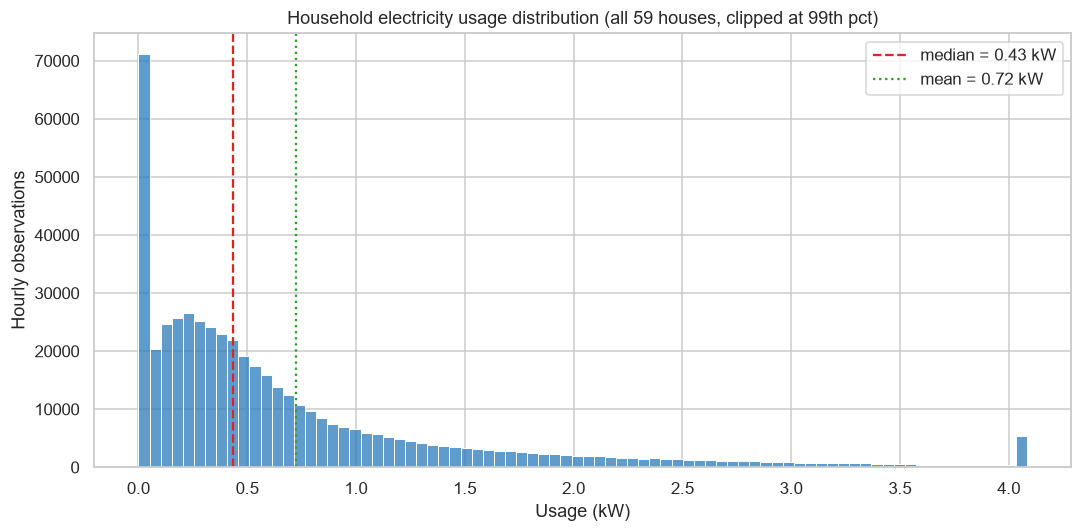

In [4]:
s = df["usage_kw"].dropna()
p99 = s.quantile(0.99)
plt.figure(figsize=(10, 5))
sns.histplot(s.clip(upper=p99), bins=80, color="#2b7bba")
plt.axvline(s.median(), color="#d62728", linestyle="--", label=f"median = {s.median():.2f} kW")
plt.axvline(s.mean(), color="#2ca02c", linestyle=":", label=f"mean = {s.mean():.2f} kW")
plt.title("Household electricity usage distribution (all 59 houses, clipped at 99th pct)")
plt.xlabel("Usage (kW)")
plt.ylabel("Hourly observations")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "01_usage_distribution.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 2 - Missing values by house and column

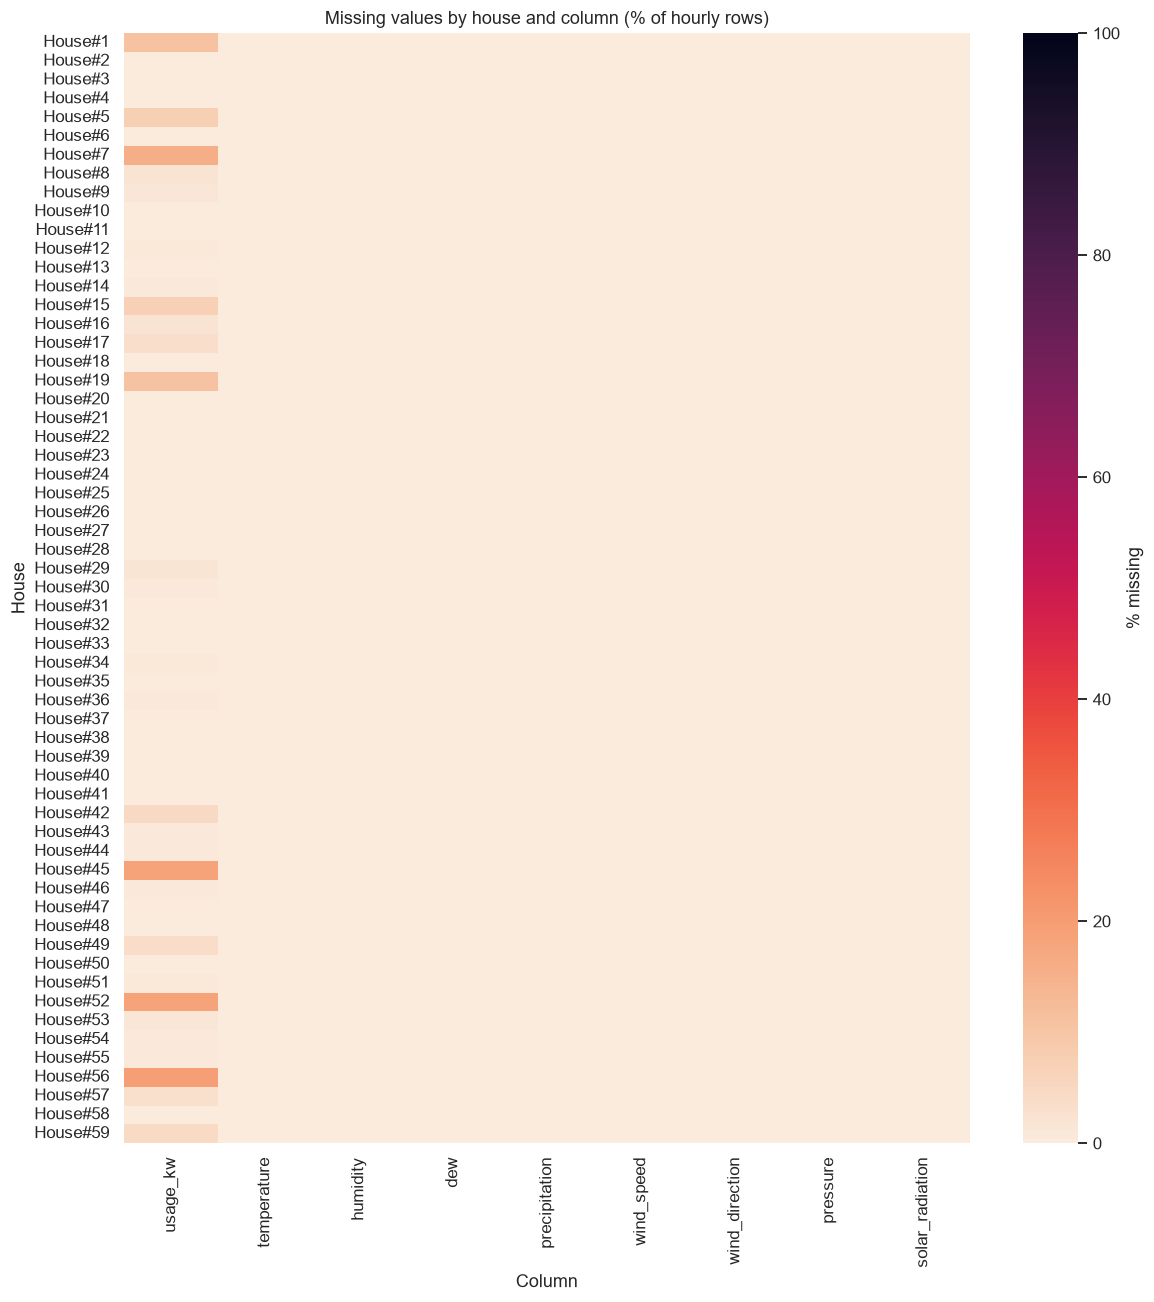

In [5]:
num_cols = ["usage_kw","temperature","humidity","dew","precipitation","wind_speed","wind_direction","pressure","solar_radiation"]
miss_house = df[num_cols].isna().groupby(df["house_id"]).mean() * 100
miss_house = miss_house.reindex(sorted(miss_house.index, key=lambda h: int(re.search(r"\d+", h).group())))
plt.figure(figsize=(11, 12))
sns.heatmap(miss_house, cmap="rocket_r", vmin=0, vmax=100, cbar_kws={"label": "% missing"})
plt.title("Missing values by house and column (% of hourly rows)")
plt.xlabel("Column")
plt.ylabel("House")
plt.tight_layout()
plt.savefig(FIG / "01_missing_values_by_house.png", dpi=220, bbox_inches="tight")
plt.show()

## 3. Duplicates and CT-378 compliance check

In [6]:
dups = df.duplicated(subset=["house_id", "datetime"]).sum()
feature_cols = [c for c in df.columns if c not in ("datetime", "house_id", "city", "usage_kw")]
print("Duplicate (house_id, datetime) rows:", dups)
print("Rows:", f"{len(df):,}", "| CT-378 minimum 5,000 ->", "PASS" if len(df) >= 5000 else "FAIL")
print("Weather feature columns:", len(feature_cols), "->", feature_cols)
print("Engineered/raw features will exceed the 15-feature minimum after Phase 3.")

Duplicate (house_id, datetime) rows: 0
Rows: 515,786 | CT-378 minimum 5,000 -> PASS
Weather feature columns: 8 -> ['temperature', 'humidity', 'dew', 'precipitation', 'wind_speed', 'wind_direction', 'pressure', 'solar_radiation']
Engineered/raw features will exceed the 15-feature minimum after Phase 3.


## Findings - Notebook 01

- The combined hourly dataset has **515,786 rows** across **59 houses** in **6 cities** - far above the CT-378 5,000-row minimum.
- **`usage_kw`** is the target; usage is right-skewed with most hours in the low single-digit kW range and a long tail.
- **Missing values**: `usage_kw` is ~2.5% missing; weather columns are ~5.6% missing only because some houses report hours outside the Open-Meteo coverage window.
- Next: deeper electricity analysis (load profiles, outliers, target bins) in **02_electricity_eda.ipynb**.